In [3]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
tips = sns.load_dataset("tips")
print(tips.shape)
print(tips.columns)

(244, 7)
Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')


In [5]:
print(tips.info())
print(tips.describe())

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000


In [6]:
print(tips['sex'].value_counts())
print(tips['smoker'].value_counts())
print(tips['day'].value_counts())
print(tips['time'].value_counts())

sex
Male      157
Female     87
Name: count, dtype: int64
smoker
No     151
Yes     93
Name: count, dtype: int64
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
time
Dinner    176
Lunch      68
Name: count, dtype: int64


In [7]:
tips.groupby('day')['total_bill'].mean()

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64

In [8]:
summary = tips.groupby('day').agg(mean=('total_bill', "mean")).sort_values(by="mean", ascending=False)

summary

,mean
day,
Sun,21.410000
Sat,20.441379
Thur,17.682742
Fri,17.151579


In [172]:
tips["bill_per_person"] = tips["total_bill"]/tips["size"]

summary = tips[(tips['size'] > 4) | (tips['size'] < 3)].groupby('size').agg(mean=('bill_per_person', "mean"))

summary

,mean
size,
1,7.242500
2,8.224006
5,6.013600
6,5.805000


In [173]:
summary = tips[['total_bill', 'tip', 'day', 'size']].sort_values(by='total_bill', ascending=False).head(10)

summary

,total_bill,tip,day,size
170,50.81,10.00,Sat,3
212,48.33,9.00,Sat,4
59,48.27,6.73,Sat,4
156,48.17,5.00,Sun,6
182,45.35,3.50,Sun,3
102,44.30,2.50,Sat,3
197,43.11,5.00,Thur,4
142,41.19,5.00,Thur,5
184,40.55,3.00,Sun,2
95,40.17,4.73,Fri,4


In [174]:
summary = tips.groupby('day').agg(count=("total_bill", "count"), mean_bill=("total_bill", 'mean'), mean_tip=("tip", "mean")).sort_values(by='mean_bill', ascending=False)

summary

,count,mean_bill,mean_tip
day,,,
Sun,76,21.410000,3.255132
Sat,87,20.441379,2.993103
Thur,62,17.682742,2.771452
Fri,19,17.151579,2.734737


In [175]:
summary = tips.groupby('day').agg(count=("total_bill", "count"), mean_bill=("total_bill", 'mean'), mean_tip=("tip", "mean")).sort_values(by='mean_bill', ascending=False)

summary = summary[summary['mean_bill'] > 20]

summary

,count,mean_bill,mean_tip
day,,,
Sun,76,21.410000,3.255132
Sat,87,20.441379,2.993103


<Axes: xlabel='total_bill', ylabel='Count'>

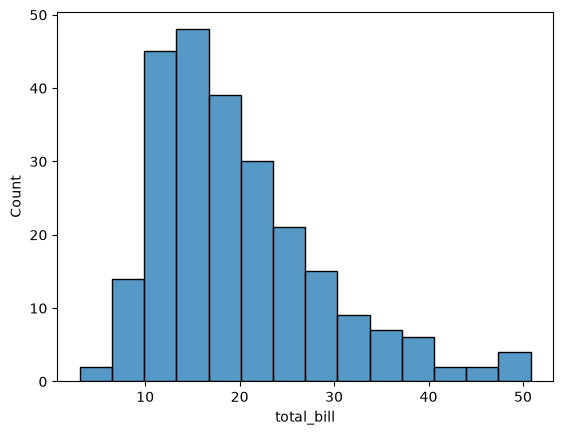

In [176]:
sns.histplot(data=tips, x="total_bill")

<Axes: xlabel='tip', ylabel='day'>

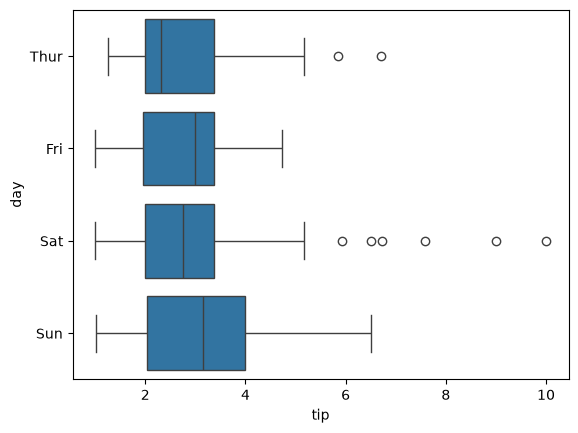

In [177]:
sns.boxplot(data=tips, x="tip", y="day")

<Axes: xlabel='total_bill', ylabel='tip'>

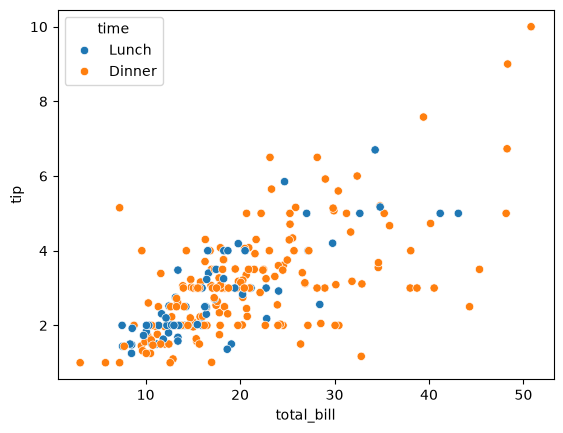

In [178]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time")

<Axes: >

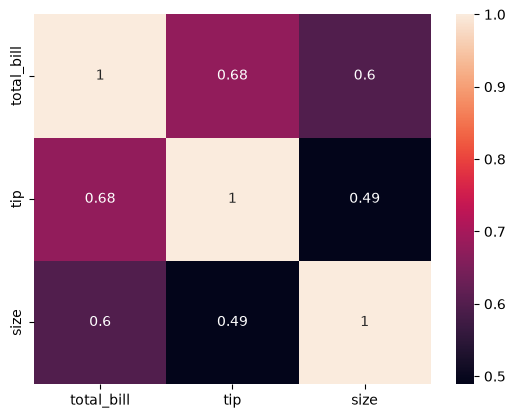

In [9]:
matrix = tips.corr(numeric_only=True)
sns.heatmap(matrix, annot=True)

In [179]:
titanic = sns.load_dataset("titanic")

print(titanic.shape)
print(titanic.columns)

(891, 15)
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')


In [180]:
print(titanic.info())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB
None


In [181]:
print(titanic.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [182]:
titanic_dirty = titanic.copy(deep=True)

# 1. Błędna wartość wieku (Age) – błąd wartości (outlier)
titanic_dirty.loc[0, 'age'] = 150

# 2. Błędna wartość fare – wartość ujemna
titanic_dirty.loc[1, 'fare'] = -50

# 3. Błędna wartość embarked – nieprawidłowa kategoria
titanic_dirty.loc[2, 'embarked'] = 'X'

# 4. Błędna wartość sex – nieprawidłowa kategoria
titanic_dirty.loc[3, 'sex'] = 'unknown'

# 5. Brak danych w kolumnie class
titanic_dirty.loc[4, 'class'] = np.nan

# 6. Błędna liczba sibsp – nieprawidłowa wartość
titanic_dirty.loc[5, 'sibsp'] = -3

In [183]:
print(titanic_dirty.duplicated().sum())
print(titanic_dirty.isna().sum())

106
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            1
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [184]:
print(titanic_dirty.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.878389    0.519641    0.381594   32.068088
std      0.486592    0.836071   15.205314    1.108905    0.806057   49.752338
min      0.000000    1.000000    0.420000   -3.000000    0.000000  -50.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.895800
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000  150.000000    8.000000    6.000000  512.329200


In [185]:
print(titanic_dirty['sex'].value_counts())

sex
male       577
female     313
unknown      1
Name: count, dtype: int64


In [186]:
print(titanic_dirty['embarked'].value_counts())

embarked
S    643
C    168
Q     77
X      1
Name: count, dtype: int64


In [187]:
titanic_dirty = titanic_dirty.drop(columns=['alive', "class", "embarked"])

titanic_dirty.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   who          891 non-null    str     
 8   adult_male   891 non-null    bool    
 9   deck         203 non-null    category
 10  embark_town  889 non-null    str     
 11  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), str(3)
memory usage: 65.7 KB


## Metody czyszczenia danych (ze skryptu):

In [188]:
titanic_clean = titanic_dirty.copy()

# titanic_clean["sex"] = titanic_clean["sex"].replace("unknown", np.nan)
# ALBO
titanic_clean = titanic_clean[titanic_clean['sex'].isin(["male", "female"])]

titanic_clean.loc[titanic_clean["fare"] < 0, "fare"] = np.nan
titanic_clean.loc[titanic_clean["age"] > 100, "age"] = np.nan

print(titanic_clean.shape, "->", titanic_clean.dropna().shape)

titanic_clean = titanic_clean.drop_duplicates()

from sklearn.impute import SimpleImputer

numeric_columns = [
  "survived", "pclass", "age", "sibsp", "parch", "fare"
]

titanic_imputed = titanic.copy()

imputer_median = SimpleImputer(strategy="median")
titanic_imputed[numeric_columns] = imputer_median.fit_transform(titanic_imputed[numeric_columns])

imputer_dom = SimpleImputer(strategy="most_frequent")
titanic_imputed[["sex", "deck", "embarked", "embark_town"]] = imputer_dom.fit_transform(titanic_imputed[["sex", "deck", "embarked", "embark_town"]])

print(titanic_imputed.isnull().sum().sum())

(890, 12) -> (180, 12)
0


In [189]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder  # noqa: F401, I001

X = titanic_imputed[numeric_columns]

X = X.dropna()

print(X.describe().round(1))

scaler_std = StandardScaler()
X_std = pd.DataFrame(scaler_std.fit_transform(X), columns = X.columns)

print(X_std.describe().round(1))

scaler_minmax = MinMaxScaler()
X_minmax = pd.DataFrame(scaler_minmax.fit_transform(X), columns=X.columns)

print(X_minmax.describe().round(1))

       survived  pclass    age  sibsp  parch   fare
count     891.0   891.0  891.0  891.0  891.0  891.0
mean        0.4     2.3   29.4    0.5    0.4   32.2
std         0.5     0.8   13.0    1.1    0.8   49.7
min         0.0     1.0    0.4    0.0    0.0    0.0
25%         0.0     2.0   22.0    0.0    0.0    7.9
50%         0.0     3.0   28.0    0.0    0.0   14.5
75%         1.0     3.0   35.0    1.0    0.0   31.0
max         1.0     3.0   80.0    8.0    6.0  512.3
       survived  pclass    age  sibsp  parch   fare
count     891.0   891.0  891.0  891.0  891.0  891.0
mean        0.0    -0.0    0.0    0.0    0.0    0.0
std         1.0     1.0    1.0    1.0    1.0    1.0
min        -0.8    -1.6   -2.2   -0.5   -0.5   -0.6
25%        -0.8    -0.4   -0.6   -0.5   -0.5   -0.5
50%        -0.8     0.8   -0.1   -0.5   -0.5   -0.4
75%         1.3     0.8    0.4    0.4   -0.5   -0.0
max         1.3     0.8    3.9    6.8    7.0    9.7
       survived  pclass    age  sibsp  parch   fare
count     89

In [190]:
category_columns = ["sex", "deck"]

X = titanic_imputed[category_columns]

encoder_onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore")


X_oh = pd.DataFrame(
    encoder_onehot.fit_transform(X),
    columns=encoder_onehot.get_feature_names_out(),
    index=X.index
)

print(X_oh)

print(X_oh.sum())

     sex_female  sex_male  deck_A  deck_B  deck_C  deck_D  deck_E  deck_F  \
0           0.0       1.0     0.0     0.0     1.0     0.0     0.0     0.0   
1           1.0       0.0     0.0     0.0     1.0     0.0     0.0     0.0   
2           1.0       0.0     0.0     0.0     1.0     0.0     0.0     0.0   
3           1.0       0.0     0.0     0.0     1.0     0.0     0.0     0.0   
4           0.0       1.0     0.0     0.0     1.0     0.0     0.0     0.0   
..          ...       ...     ...     ...     ...     ...     ...     ...   
886         0.0       1.0     0.0     0.0     1.0     0.0     0.0     0.0   
887         1.0       0.0     0.0     1.0     0.0     0.0     0.0     0.0   
888         1.0       0.0     0.0     0.0     1.0     0.0     0.0     0.0   
889         0.0       1.0     0.0     0.0     1.0     0.0     0.0     0.0   
890         0.0       1.0     0.0     0.0     1.0     0.0     0.0     0.0   

     deck_G  
0       0.0  
1       0.0  
2       0.0  
3       0.0  
4    

In [191]:
from sklearn.model_selection import train_test_split

numeric_columns = [
  "survived", "pclass", "age", "sibsp", "parch", "fare"
]

X = titanic_imputed[numeric_columns]

y = titanic_imputed["sex"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)

print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

scaler = StandardScaler().fit(X_train) # nie ma przecieku danych
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns = X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns = X_train.columns)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

print(X_test.describe())
print(X_test_scaled.describe())

(712, 6)
(179, 6)
sex
male      0.647472
female    0.352528
Name: proportion, dtype: float64
sex
male      0.648045
female    0.351955
Name: proportion, dtype: float64
(712, 6)
(179, 6)
         survived      pclass         age       sibsp       parch        fare
count  179.000000  179.000000  179.000000  179.000000  179.000000  179.000000
mean     0.363128    2.251397   29.025140    0.430168    0.413408   35.868879
std      0.482250    0.826823   12.320971    1.070223    0.819042   66.813112
min      0.000000    1.000000    0.670000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   23.000000    0.000000    0.000000    7.987500
50%      0.000000    2.000000   28.000000    0.000000    0.000000   14.400000
75%      1.000000    3.000000   34.500000    1.000000    0.000000   30.000000
max      1.000000    3.000000   62.000000    8.000000    5.000000  512.329200
         survived      pclass         age       sibsp       parch        fare
count  179.000000  179.000000  179

In [192]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

category_columns = ["sex", "deck"]
numeric_columns = [
  "survived", "pclass", "age", "sibsp", "parch", "fare"
]

numeric_pipeline = Pipeline([
  ("imputer", SimpleImputer(strategy="median")), 
  ("scaler", StandardScaler())
])

category_pipeline = Pipeline([
  ("imputer", SimpleImputer(strategy="most_frequent")),
  ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
  ("numeric", numeric_pipeline, numeric_columns),
  ("category", category_pipeline, category_columns)
])

X = titanic_imputed[numeric_columns + category_columns]
y = titanic_imputed["alone"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape, X_test_processed.shape)
print(preprocessor.get_feature_names_out())

(712, 15) (179, 15)
['numeric__survived' 'numeric__pclass' 'numeric__age' 'numeric__sibsp'
 'numeric__parch' 'numeric__fare' 'category__sex_female'
 'category__sex_male' 'category__deck_A' 'category__deck_B'
 'category__deck_C' 'category__deck_D' 'category__deck_E'
 'category__deck_F' 'category__deck_G']


In [193]:
import joblib

joblib.dump(preprocessor, "output/preprocessor.joblib")
loaded_preprocessor = joblib.load("output/preprocessor.joblib")

In [194]:
from sklearn.decomposition import PCA

X_numeric = titanic_imputed[numeric_columns]

scaler = StandardScaler()

X_std = scaler.fit_transform(X_numeric)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_std)

print(pca.explained_variance_ratio_.round(2))
print(X_pca)

[0.31 0.27 0.16]
[[ 1.33693358  0.26388613 -0.15746871]
 [-2.08794272 -0.39369322  0.28922032]
 [ 0.42893236 -0.30971199  1.41769031]
 ...
 [ 0.68070548  1.57301173 -0.95400014]
 [-1.33952086 -0.6576667   1.20038384]
 [ 1.17307101 -0.64632051 -0.3318371 ]]


In [195]:
values = pd.DataFrame(pca.components_[:2], columns=numeric_columns, index=["PC1", "PC2"])
print(values.round(2))

     survived  pclass   age  sibsp  parch  fare
PC1     -0.42    0.63 -0.24  -0.03  -0.14 -0.59
PC2      0.06    0.17 -0.46   0.61   0.59  0.16


In [196]:
pca_pipeline = Pipeline([
("preprocessing", preprocessor), ("pca", PCA(n_components=2))
])
X_train_2d = pca_pipeline.fit_transform(X_train)
print(X_train_2d.shape) 

(712, 2)


In [197]:
rng = np.random.default_rng(42)

train_data = X_train.dropna().copy()

train_data["alone"] = y_train.loc[train_data.index]

augumented_data = train_data.copy()

print(augumented_data.info())

feature_std = train_data[numeric_columns].std()
noise = rng.normal(loc=0, scale=0.02 * feature_std.values, size=train_data[numeric_columns].shape)

augumented_data[numeric_columns] = (train_data[numeric_columns] + noise)

print(augumented_data.info())

augumented_train_data = pd.concat([train_data, augumented_data], ignore_index=True)

print(augumented_train_data.info())

<class 'pandas.DataFrame'>
Index: 712 entries, 867 to 196
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  712 non-null    float64
 1   pclass    712 non-null    float64
 2   age       712 non-null    float64
 3   sibsp     712 non-null    float64
 4   parch     712 non-null    float64
 5   fare      712 non-null    float64
 6   sex       712 non-null    str    
 7   deck      712 non-null    str    
 8   alone     712 non-null    bool   
dtypes: bool(1), float64(6), str(2)
memory usage: 50.8 KB
None
<class 'pandas.DataFrame'>
Index: 712 entries, 867 to 196
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  712 non-null    float64
 1   pclass    712 non-null    float64
 2   age       712 non-null    float64
 3   sibsp     712 non-null    float64
 4   parch     712 non-null    float64
 5   fare      712 non-null    float64
 6   sex       7

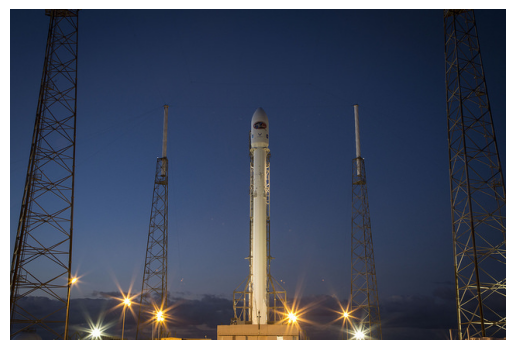

In [198]:
from skimage import data

obraz = data.rocket()

plt.imshow(obraz)
plt.axis(False)
plt.show()

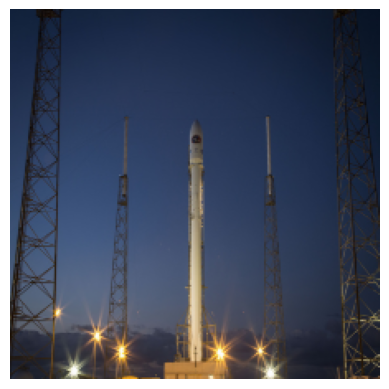

In [199]:
from skimage import color, transform

pomniejszony = transform.resize(obraz, (224,224))

plt.imshow(pomniejszony)
plt.axis(False)
plt.show()

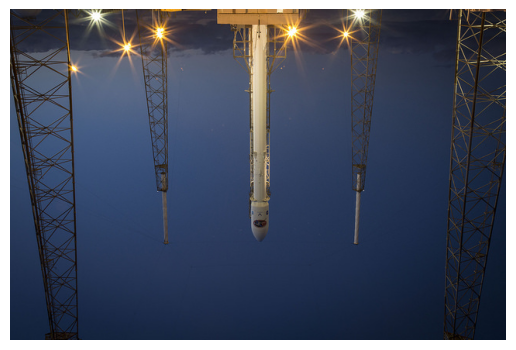

In [200]:
flipped = obraz[::-1, :]

plt.imshow(flipped)
plt.axis(False)
plt.show()

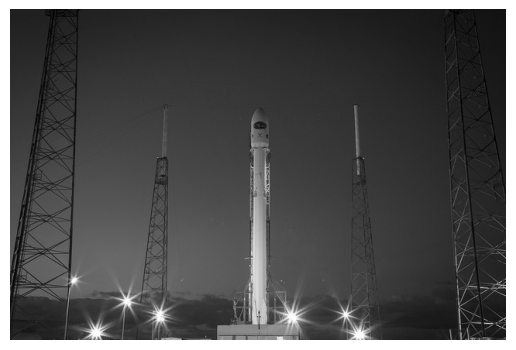

In [201]:
gray = color.rgb2gray(obraz)

plt.imshow(gray, cmap="gray")
plt.axis(False)
plt.show()

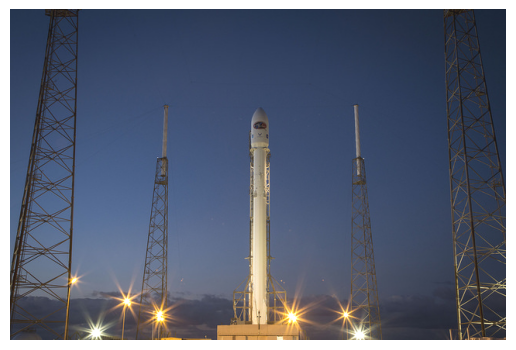

In [202]:
bright = np.clip(obraz.astype(np.int16) + 20, 0, 255).astype(np.uint8)

plt.imshow(bright)
plt.axis(False)
plt.show()

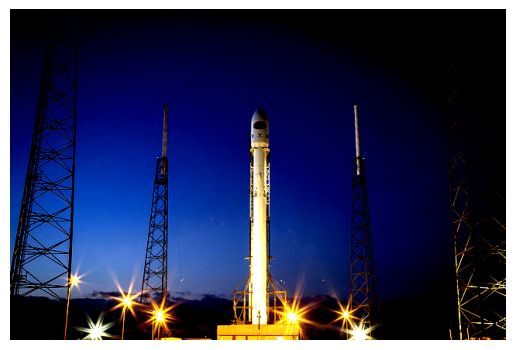

In [203]:
bright = np.clip((obraz.astype(np.float32) - 64) * 3, 0, 255).astype(np.uint8)

plt.imshow(bright)
plt.axis(False)
plt.show()

In [204]:
wrong = obraz + 100

print((wrong < obraz).sum())

15248


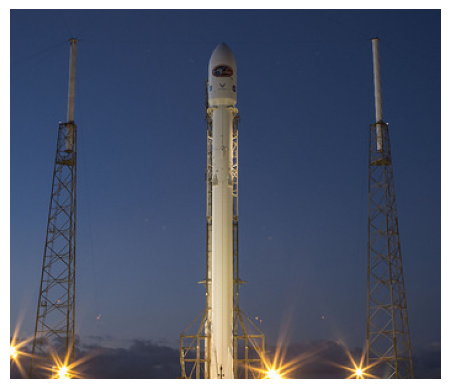

In [205]:
cropped = obraz[100:400, 150:500]

plt.imshow(cropped)
plt.axis(False)
plt.show()

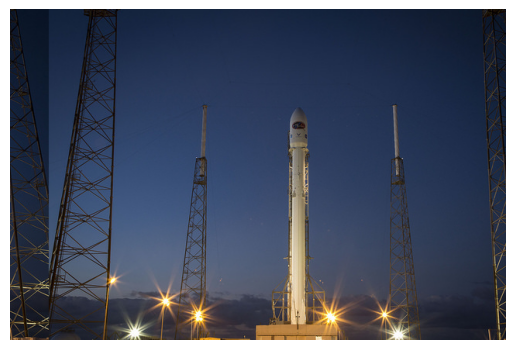

In [206]:
rolled = np.roll(obraz, shift=50, axis=1) # 50 px w prawo

plt.imshow(rolled)
plt.axis(False)
plt.show()

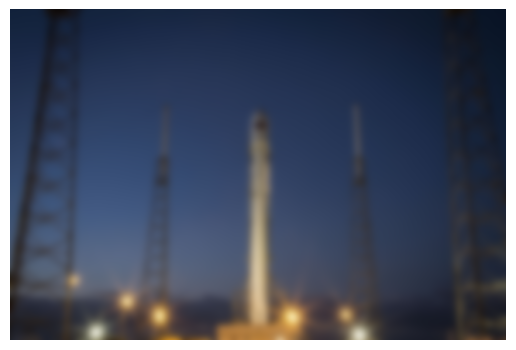

In [207]:
from skimage import filters

blurred = filters.gaussian(obraz, sigma=5, channel_axis=-1)

plt.imshow(blurred)
plt.axis(False)
plt.show()

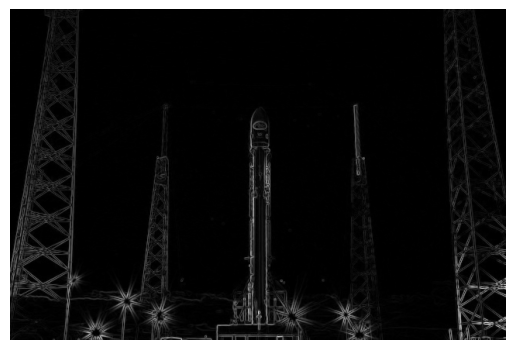

In [208]:
sobel = filters.sobel(gray)

plt.imshow(sobel, cmap="gray")
plt.axis(False)
plt.show()

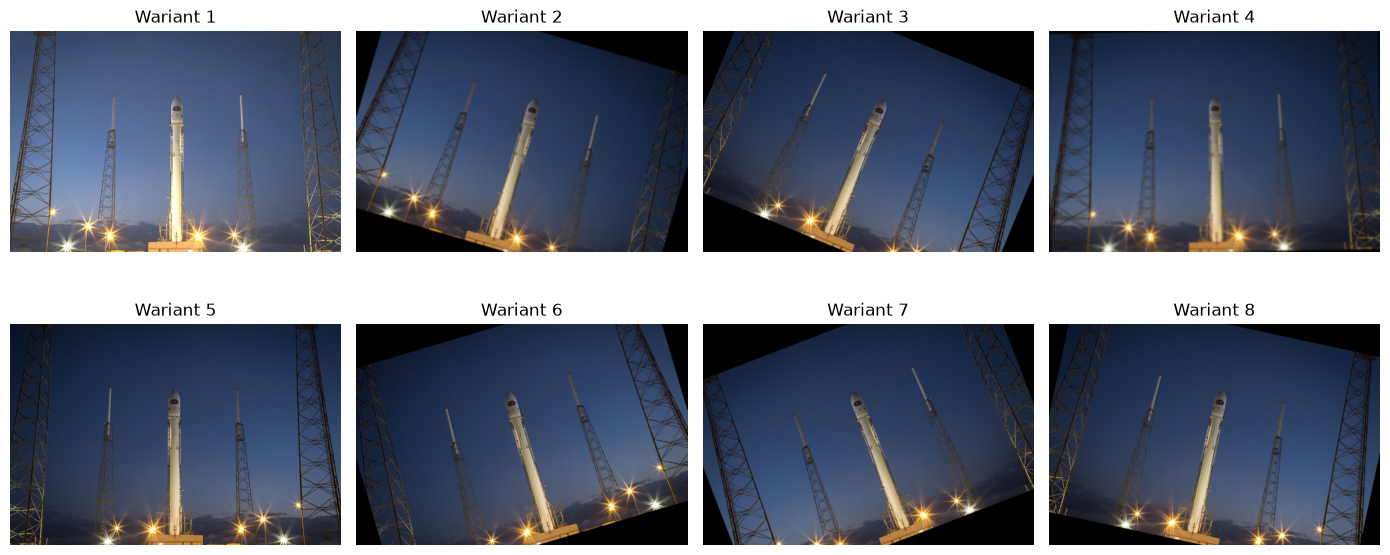

In [209]:
import albumentations as A

pipeline = A.Compose([
  A.HorizontalFlip(p=0.5),
A.Rotate(limit=25, p=0.5), 
A.RandomBrightnessContrast(p=0.3), 
A.GaussianBlur(blur_limit=(3, 7), p=0.2),
])

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for i, ax in enumerate(axes.flat):
  augmented = pipeline(image=obraz)["image"] 
  ax.imshow(augmented)
  ax.set_title(f"Wariant {i + 1}")
  ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def cosine_similarity(a, b):
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def cosine_similarity_images(a,b):
  vector_a = a.astype(np.float32).flatten()
  vector_b = b.astype(np.float32).flatten()

  return cosine_similarity(vector_a, vector_b)

other = transform.resize(data.chelsea(), (224, 224))

print(round(cosine_similarity_images(obraz, rolled), 4))
print(round(cosine_similarity_images(obraz, bright), 4))
print(round(cosine_similarity_images(pomniejszony, other), 4))

0.8992
0.8292
0.8013
